# Figure 4 — ESCALADE accelerates both methods equally

The closed-form single-qubit propagator jet, verified against the library's
own, then timed against it component by component.

In [1]:
from common import *


---

# Figure 4 — ESCALADE accelerates both methods equally

Goodwin & Vinding's ESCALADE replaces the per-gate matrix exponential and its
derivatives with a closed form. It applies when the generators of one gate are
pairwise anticommuting involutions, $\{B_j, B_k\} = 2\delta_{jk}\mathbb 1$,
which collapses $A^2$ to a multiple of the identity and with it the whole
exponential series. The setting is therefore **one qubit** — $x$ and $y$
control with a fixed $z$ offset, Goodwin & Vinding's Eq. (3) — and not the
Rydberg array of Figures 1–3: $\{X, Y, Z\}$ anticommute pairwise and the
two-qubit Pauli basis does not, since e.g. $XI$ and $XX$ commute.

It is implemented here through **second** order, so it accelerates the Newton
Hessian and not only GEOPE's Jacobian. Both methods propagate the *same* chart,
so replacing the per-gate step multiplies both sides by the same factor — which
is the point of this section. It changes what an iteration costs in Figure 2,
not which method is cheaper.

Nothing here monkey-patches `geope`. The propagators in `geope.jax` take their
per-gate callables as ordinary arguments, so the two routes share geope's
prefix/suffix passes verbatim and differ *only* in the per-gate step, which is
what makes a timing difference attributable to ESCALADE.

## The closed form

One gate of geope's chart is $U = \exp(i\sum_k\phi_kB_k)$. Write
$A = \sum_k\phi_kB_k$, $t = |\phi|^2$ and $\rho = \sqrt t$. *If* the generators
are pairwise anticommuting Hermitian involutions then $A^2 = t\,\mathbb 1$, the
series collapses, and everything below is a derivative of

$$U = \cos\rho\,\mathbb 1 + i\,S\,A, \qquad
  S = \frac{\sin\rho}{\rho}, \quad
  S_1 = \frac{\mathrm dS}{\mathrm dt}, \quad
  S_2 = \frac{\mathrm dS_1}{\mathrm dt},$$

with no matrix exponential, no eigendecomposition and no auxiliary matrix.

Working in $t$ rather than $\rho$ is deliberate: $S$, $S_1$ and $S_2$ are even
in $\rho$ and hence single-valued in $t$, and differentiating with respect to
$t$ — where $\partial t/\partial\phi_k = 2\phi_k$ — keeps every $1/\rho$ out of
the formulas. Nothing here is singular at $\phi = 0$.

In [2]:
TINY = 1e-4  # switch to the series below this |t|


def assert_anticommuting(basis, atol=1e-12):
    r"""Raise unless ``basis`` is a frame of pairwise anticommuting involutions.

    ESCALADE needs $\{B_j,B_k\} = 2\delta_{jk}\mathbb 1$ — the identity that
    collapses $A^2$ to $|\phi|^2\mathbb 1$. The $j = k$ diagonal of that
    condition is $B_j^2 = \mathbb 1$, so this one check covers the involution
    property too.

    It holds for any subset of $\{X, Y, Z\}$ and fails for the full Pauli basis
    of two or more qubits. Every route builder below calls it, so the closed
    form can never be used on a frame it is wrong for.

    Args:
        basis: ``(K, d, d)`` generator frame.
        atol: Absolute tolerance on the anticommutator.

    Returns:
        The maximum deviation, for reporting.
    """
    b = jnp.asarray(basis)
    k, d = b.shape[0], b.shape[-1]
    prod = jnp.einsum("jab,kbc->jkac", b, b)
    anti = prod + jnp.swapaxes(prod, 0, 1)
    want = 2.0 * jnp.eye(k)[:, :, None, None] * jnp.eye(d)[None, None, :, :]
    err = float(jnp.max(jnp.abs(anti - want)))
    if err > atol:
        raise ValueError(
            f"generators are not pairwise anticommuting involutions "
            f"(max |{{B_j,B_k}} - 2 delta_jk| = {err:.2e}); ESCALADE's closed "
            f"form does not apply to this frame"
        )
    return err


def escalade_coeffs(t):
    r"""The three scalars, as functions of $t = |\phi|^2$.

    $$S=\frac{\sin\rho}{\rho},\qquad
      S_1=\frac{\mathrm dS}{\mathrm dt}=\frac{\rho\cos\rho-\sin\rho}{2\rho^3},$$
    $$S_2=\frac{\mathrm dS_1}{\mathrm dt}
        =\frac{(6-2\rho^2)\sin\rho-6\rho\cos\rho}{8\rho^5}.$$

    $S_1$ and $S_2$ difference quantities of size $\rho$ to produce ones of size
    $\rho^3$ and $\rho^5$, so both lose accuracy near the origin and are
    evaluated by their Taylor series there instead. The ``where`` on ``t``
    *before* the division is what keeps the unused branch from producing a
    ``nan``: XLA evaluates both arms of a ``where``. The predicate tests
    ``jnp.abs`` because the pipeline hands these functions ``complex128`` with a
    zero imaginary part.
    """
    small = jnp.abs(t) < TINY
    t_safe = jnp.where(small, jnp.ones_like(t), t)
    rho = jnp.sqrt(t_safe)
    sin, cos = jnp.sin(rho), jnp.cos(rho)
    S = jnp.where(small, 1.0 - t / 6.0 + t**2 / 120.0, sin / rho)
    S1 = jnp.where(
        small,
        -1.0 / 6.0 + t / 60.0 - t**2 / 1680.0,
        (rho * cos - sin) / (2.0 * t_safe * rho),
    )
    S2 = jnp.where(
        small,
        1.0 / 60.0 - t / 840.0,
        ((6.0 - 2.0 * t_safe) * sin - 6.0 * rho * cos) / (8.0 * t_safe**2 * rho),
    )
    return S, S1, S2


def escalade_gate(phi, basis):
    r"""One gate $U = \exp(i\sum_k\phi_kB_k)$, with no matrix exponential.

    The drop-in for `geope.jax.Ui`. $\cos\sqrt t$ needs no small-$t$ branch: it
    is even in $\rho$ and perfectly conditioned at the origin.
    """
    t = jnp.sum(phi**2)
    S, _S1, _S2 = escalade_coeffs(t)
    A = jnp.tensordot(phi, basis, axes=[[0], [0]])
    return jnp.cos(jnp.sqrt(t)) * jnp.eye(basis.shape[-1], dtype=A.dtype) + 1j * S * A


def escalade_jac(phi, basis):
    r"""$\partial U/\partial\phi_k$ for every $k$ at once, shape ``(d, d, K)``.

    $$\frac{\partial U}{\partial\phi_k}
      = -\phi_kS\,\mathbb 1 + i\bigl(2\phi_kS_1A + S\,B_k\bigr).$$

    The drop-in for `geope.jax.dexpm_eig`: no eigendecomposition, no divided
    differences, no auxiliary matrix — one `sin`, one `cos` and a few rank-one
    updates.
    """
    t = jnp.sum(phi**2)
    S, S1, _S2 = escalade_coeffs(t)
    A = jnp.tensordot(phi, basis, axes=[[0], [0]])
    eye = jnp.eye(basis.shape[-1], dtype=A.dtype)
    columns = jnp.moveaxis(basis, 0, -1)  # (d, d, K)
    return -phi * S * eye[:, :, None] + 1j * (
        2.0 * S1 * phi * A[:, :, None] + S * columns
    )


def escalade_adj(phi, b, basis):
    r"""$\mathrm{Tr}(b^\dagger\partial_kU)$ for every $k$, shape ``(K,)``.

    The drop-in for `geope.jax.adj_expm_eig`: all $K$ overlaps of one covector
    out of $K+2$ traces, never forming the tensor `escalade_jac` returns.
    Complex and **un-halved**, matching `geope.jax.vjp_propagator`'s contract —
    a real gradient takes ``2 * jnp.real(...)``.
    """
    t = jnp.sum(phi**2)
    S, S1, _S2 = escalade_coeffs(t)
    overlaps = jnp.einsum("ab,kab->k", jnp.conj(b), basis)  # Tr(b^dag B_k)
    trace = jnp.conj(jnp.trace(b))  # Tr(b^dag 1)
    overlap_A = jnp.dot(phi, overlaps)  # Tr(b^dag A)
    return -phi * S * trace + 1j * (2.0 * S1 * phi * overlap_A + S * overlaps)


def escalade_d2(phi, basis):
    r"""$\partial^2U/\partial\phi_j\partial\phi_k$, shape ``(d, d, K, K)``.

    Differentiating `escalade_jac` once more,

    $$\frac{\partial^2U}{\partial\phi_j\partial\phi_k}
      = -\bigl(\delta_{jk}S + 2\phi_j\phi_kS_1\bigr)\mathbb 1
      + i\bigl[2\delta_{jk}S_1A + 4\phi_j\phi_kS_2A
             + 2\phi_kS_1B_j + 2\phi_jS_1B_k\bigr].$$

    The drop-in for `geope.jax.d2expm_eig`, and what makes a **Newton** step
    ESCALADE-accelerated rather than only GEOPE's Jacobian. Manifestly symmetric
    in $(j,k)$, as the mixed partial must be.
    """
    t = jnp.sum(phi**2)
    S, S1, S2 = escalade_coeffs(t)
    A = jnp.tensordot(phi, basis, axes=[[0], [0]])
    d, k = basis.shape[-1], basis.shape[0]
    eye = jnp.eye(d, dtype=A.dtype)
    kronecker = jnp.eye(k, dtype=phi.dtype)
    outer_j, outer_k = phi[:, None], phi[None, :]
    columns = jnp.moveaxis(basis, 0, -1)  # (d, d, K)

    scalar_eye = -(kronecker * S + 2.0 * outer_j * outer_k * S1)
    scalar_A = 1j * (2.0 * kronecker * S1 + 4.0 * outer_j * outer_k * S2)
    out = (
        scalar_eye[None, None, :, :] * eye[:, :, None, None]
        + scalar_A[None, None, :, :] * A[:, :, None, None]
    )
    return out + 2j * S1 * (
        outer_k[None, None, :, :] * columns[:, :, :, None]
        + outer_j[None, None, :, :] * columns[:, :, None, :]
    )


def escalade_hvp_step(phi, p, basis):
    r"""$(U,\ \mathrm DU[p],\ \mathrm D^2U[p,p])$ for one direction.

    The drop-in for `geope.jax.expm_hvp_eig`. Contracting `escalade_jac` and
    `escalade_d2` against $p$ collapses every index sum to three scalars —
    $\phi\!\cdot\!p$, $|p|^2$ and $P=\sum_kp_kB_k$ — so the rank-3 and rank-4
    tensors are never formed:

    $$E = -(\phi\!\cdot\!p)S\,\mathbb 1
        + i\bigl(2(\phi\!\cdot\!p)S_1A + S\,P\bigr),$$
    $$G = -\bigl(|p|^2S + 2(\phi\!\cdot\!p)^2S_1\bigr)\mathbb 1
        + i\bigl(2|p|^2S_1A + 4(\phi\!\cdot\!p)^2S_2A
               + 4(\phi\!\cdot\!p)S_1P\bigr).$$
    """
    t = jnp.sum(phi**2)
    S, S1, S2 = escalade_coeffs(t)
    A = jnp.tensordot(phi, basis, axes=[[0], [0]])
    P = jnp.tensordot(p, basis, axes=[[0], [0]])
    eye = jnp.eye(basis.shape[-1], dtype=A.dtype)
    phi_p = jnp.sum(phi * p)
    p_p = jnp.sum(p * p)

    point = jnp.cos(jnp.sqrt(t)) * eye + 1j * S * A
    velocity = -phi_p * S * eye + 1j * (2.0 * phi_p * S1 * A + S * P)
    acceleration = -(p_p * S + 2.0 * phi_p**2 * S1) * eye + 1j * (
        2.0 * p_p * S1 * A + 4.0 * phi_p**2 * S2 * A + 4.0 * phi_p * S1 * P
    )
    return point, velocity, acceleration

## Wiring it into the pipeline

`geope.jax`'s propagators take their per-gate callables as ordinary arguments
and `vmap`/`scan` them over gates, so the ESCALADE and spectral routes share
geope's prefix/suffix passes verbatim. On a matrix Lie group `base_point` is
`None`, so `geope.geometry.chart`'s landing is the identity and the four
factories below are exactly what `Manifold.bind` would hang off the
`TangentBundle` — which is why one `dataclasses.replace` is the whole
intervention.

In [3]:
def escalade_chart_fn(basis):
    """``phi -> U``: the product of ESCALADE gates. `get_chart_fn`'s job.

    geope's convention is left multiplication, ``U <- U_i U`` seeded at the
    identity, so the gates compose in the same order as the spectral route.
    """
    d = basis.shape[-1]
    gate_fn = partial(escalade_gate, basis=basis)

    def chart(params_list):
        gates = jax.vmap(gate_fn)(params_list)
        eye = jnp.eye(d, dtype=gates.dtype)
        return jax.lax.scan(lambda U, g: (g @ U, None), eye, gates)[0]

    return chart


def escalade_jacobian_fn(basis):
    """``phi -> (d, d, G, K)``: the `TangentBundle.jacobian` contract."""
    jac = partial(
        jacobian_propagator,
        Ui_fn=partial(escalade_gate, basis=basis),
        jac_fn=partial(escalade_jac, basis=basis),
    )
    return lambda params_list: jnp.moveaxis(jac(params_list), 0, -2)


def escalade_vjp_fn(basis):
    """``phi -> (point, pullback)``: the `TangentBundle.vjp` contract."""
    return partial(
        vjp_propagator,
        Ui_fn=partial(escalade_gate, basis=basis),
        adj_fn=partial(escalade_adj, basis=basis),
    )


def escalade_hvp_fn(basis):
    """``(phi, p) -> (U, E, G)``: the `TangentBundle.hvp` contract."""
    return partial(hvp_propagator, step_fn=partial(escalade_hvp_step, basis=basis))


def escalade_hessian_vjp_fn(basis):
    """``phi -> (point, pullback)``: the `TangentBundle.hessian_vjp` contract.

    This is the one that matters for the Newton comparison: `Manifold.hessian`
    reads it, so swapping it is what puts the **cost Hessian** on the ESCALADE
    route rather than the spectral one.
    """
    return partial(
        hessian_vjp_propagator,
        Ui_fn=partial(escalade_gate, basis=basis),
        jac_fn=partial(escalade_jac, basis=basis),
        hess_step_fn=partial(escalade_d2, basis=basis),
    )


def escalade_manifold(manifold):
    """A copy of ``manifold`` whose chart and **all four** differentials are ESCALADE's.

    `Manifold` and `TangentBundle` are both frozen dataclasses holding
    ``compute_point`` and ``tangent`` as plain fields, so `dataclasses.replace`
    hands back an instance whose `functools.cached_property` caches
    (``fidelity_at``, ``infidelity_at``, ``value_and_grad``, ``hessian``,
    ``_project``) are empty, and it bypasses the ``is_bound`` re-bind guard —
    both of which are what we want. Nothing on `Parameters` needs invalidating:
    its cached properties are all *inputs* to ``bind``, not outputs.

    ``hvp`` and ``hessian_vjp`` go together with ``jacobian`` and ``vjp``
    because `TangentBundle.__post_init__` pins
    ``generators``/``hvp``/``hessian_vjp`` as all-or-none — and because a
    half-swapped manifold would silently time the spectral Hessian against the
    ESCALADE Jacobian.
    """
    basis = jnp.asarray(manifold.tangent.generators.basis)
    assert_anticommuting(basis)
    tangent = dataclasses.replace(
        manifold.tangent,
        jacobian=escalade_jacobian_fn(basis),
        vjp=escalade_vjp_fn(basis),
        hvp=escalade_hvp_fn(basis),
        hessian_vjp=escalade_hessian_vjp_fn(basis),
    )
    return dataclasses.replace(
        manifold, compute_point=escalade_chart_fn(basis), tangent=tangent
    )


#: The one-qubit problem, kept as constants because they key the cache below.
ESC_OFFSET = 0.5  # the fixed z resonance offset
ESC_SPREAD = 0.5  # initial pulse spread, in units of pi
ESC_SEED = 0


def one_qubit_parameters(steps, escalade=False):
    r"""One qubit, $x$ and $y$ control, a fixed $z$ offset — where ESCALADE applies.

    Goodwin & Vinding's Eq. (3): two transverse controls and a time-independent
    resonance offset. The drift column is differentiated like any other and then
    dropped by ``TangentBundle.restrict``, so ESCALADE sees all three
    generators — and $\{X, Y, Z\}$ anticommute pairwise, which is what it needs.

    Unlike `make_parameters` this is a *one*-qubit array with no interaction
    drift, because the Rydberg basis of Figures 1–3 does not anticommute.

    The manifold is swapped **before** any optimiser is built: `Geope` and
    `Grape` close over the manifold at trace time and memoise the compiled step,
    so a swap after a first ``optimize()`` would be silently ignored.
    """
    params = Parameters(
        basis=construct_full_pauli_basis(1),
        control={1: ["x", "y"]},
        drift={1: ["z"]},
        drift_values={1: {"z": ESC_OFFSET}},
        target=qft_unitary(1),  # the one-qubit QFT *is* the Hadamard
        piecewise_steps=steps,
        init_spread=ESC_SPREAD,
        seed=ESC_SEED,
    )
    if escalade:
        params.manifold = escalade_manifold(params.manifold)
    return params

## Verify that ESCALADE is exact

Against `geope.jax`'s spectral route, over $\rho = |\phi|$ from $0$ to well past
$2\pi$ — the whole jet, not only the gate: $U$, $\partial_kU$, the adjoint
$\mathrm{Tr}(b^\dagger\partial_kU)$, $\partial^2_{jk}U$, and the two directional
derivatives the HVP returns. The guard is checked as well: it must accept
$\{X,Y,Z\}$ and refuse the two-qubit Pauli basis.

In [4]:
BASIS_1Q = jnp.asarray(construct_full_pauli_basis(1).basis)  # X, Y, Z
print(f"one qubit : anticommutator residual {assert_anticommuting(BASIS_1Q):.1e}")
try:
    assert_anticommuting(jnp.asarray(construct_full_pauli_basis(2).basis))
except ValueError as exc:
    print(f"two qubits: refused, as it must be -- {str(exc)[:64]}...")
else:
    raise AssertionError("the guard did not bite on a two-qubit Pauli basis")

rng = np.random.default_rng(0)
rows = []
for rho in [0.0, 1e-6, 1e-3, 1e-2, 0.1, 1.0, np.pi, 2 * np.pi, 10.0]:
    v = rng.normal(size=3)
    phi = jnp.asarray(rho * v / np.linalg.norm(v), dtype=jnp.complex128)
    p = jnp.asarray(rng.normal(size=3), dtype=jnp.complex128)
    cov = rng.normal(size=(2, 2, 2))
    cov = jnp.asarray(cov[0] + 1j * cov[1], dtype=jnp.complex128)
    _u, e_esc, g_esc = escalade_hvp_step(phi, p, BASIS_1Q)
    _ur, e_ref, g_ref = expm_hvp_eig(phi, p, BASIS_1Q)
    rows.append(
        {
            "rho": rho,
            "U": float(
                jnp.max(jnp.abs(escalade_gate(phi, BASIS_1Q) - Ui(phi, BASIS_1Q)))
            ),
            "dU": float(
                jnp.max(jnp.abs(escalade_jac(phi, BASIS_1Q) - dexpm_eig(phi, BASIS_1Q)))
            ),
            "adjoint": float(
                jnp.max(
                    jnp.abs(
                        escalade_adj(phi, cov, BASIS_1Q)
                        - adj_expm_eig(phi, cov, BASIS_1Q)
                    )
                )
            ),
            "d2U": float(
                jnp.max(jnp.abs(escalade_d2(phi, BASIS_1Q) - d2expm_eig(phi, BASIS_1Q)))
            ),
            "hvp E": float(jnp.max(jnp.abs(e_esc - e_ref))),
            "hvp G": float(jnp.max(jnp.abs(g_esc - g_ref))),
        }
    )
checks = pd.DataFrame(rows)
print()
print(checks.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
worst = checks.drop(columns="rho").to_numpy().max()
print(f"\nworst deviation over the sweep: {worst:.2e}")
assert worst < 1e-9, f"ESCALADE disagrees with the library at {worst:.2e}"
print(
    "The one row above 1e-14 is rho = 1e-6, and it is the *reference* that loses\n"
    "accuracy there: d2expm_eig's second divided differences are ill-conditioned at\n"
    "a near-degenerate spectrum, where ESCALADE's closed form is exact."
)

one qubit : anticommutator residual 0.0e+00
two qubits: refused, as it must be -- generators are not pairwise anticommuting involutions (max |{B_j...

     rho        U       dU  adjoint      d2U    hvp E    hvp G
0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 1.89e-18
1.00e-06 1.11e-16 4.72e-16 4.97e-16 3.27e-10 4.47e-16 2.94e-10
1.00e-03 1.11e-16 4.44e-16 4.97e-16 3.86e-14 2.25e-16 1.11e-14
1.00e-02 4.34e-18 1.22e-15 1.20e-15 1.89e-15 2.22e-15 9.78e-15
1.00e-01 1.11e-16 4.46e-16 1.88e-15 1.09e-15 4.71e-16 1.59e-15
1.00e+00 2.22e-16 4.00e-16 5.24e-16 3.34e-16 6.75e-16 1.90e-15
3.14e+00 1.19e-16 3.38e-16 4.00e-16 5.66e-16 3.33e-16 9.42e-16
6.28e+00 2.16e-14 6.21e-16 1.51e-15 3.86e-16 7.77e-16 6.68e-16
1.00e+01 1.58e-15 4.93e-15 6.15e-15 4.87e-15 6.19e-15 7.55e-15

worst deviation over the sweep: 3.27e-10
The one row above 1e-14 is rho = 1e-6, and it is the *reference* that loses
accuracy there: d2expm_eig's second divided differences are ill-conditioned at
a near-degenerate spec

## Timing the two routes

The same decomposition as Figure 2, minus the solves — the solves are downstream
of the chart and ESCALADE cannot touch them. GEOPE's Jacobian line is
`ctx.omegas` alone, so no logarithm enters it, which makes the speedups
attributable per component. `chart` is timed as the per-gate propagator all
three derivatives contain; it is not a step, so the figure does not draw it.

Caching follows the rest of the notebook: one block per `(route, piece, L)`
under `geope_v2_cache/escalade/<route>/<piece>/`, keyed on a sha1 of everything
that changes the numbers. `ESC_REPEATS` is deliberately **not** in that key and
batches are stored individually, so a block timed with 5 *contains* the first 5
of a run asking for 8. `ESC_ROUNDS` *is* in the key, because it sets the
chunking the median is over.

In [5]:
L_ESC = [25, 50, 100, 250, 500, 1000]
#: `chart` is timed but not drawn: it is the per-gate propagator all three
#: derivatives contain, not a step of either method.
ESC_PIECES = ("chart", "GEOPE: Jacobian", "Newton: gradient", "Newton: Hessian")
ESC_ROUTES = ("live", "ESCALADE")
ESC_ROUNDS, ESC_WARMUP, ESC_REPEATS = 25, 7, 5


def escalade_components(steps, route):
    """The four pieces of one iteration on one route, as jitted callables.

    Unlike `cost_components` there is nothing to gate on: every piece here is a
    lazily-jitted callable over a one-qubit chart, so building one it does not
    time costs a closure and no compilation.
    """
    params = one_qubit_parameters(steps, escalade=(route == "ESCALADE"))
    Geope(params)  # writes the drift columns before any Jacobian is read
    manifold = params.manifold
    free = params.free()

    @jax.jit
    def geope_jacobian(phi):
        return manifold.context(phi).omegas

    pieces = {
        "chart": (jax.jit(manifold.compute_point), (free,)),
        "GEOPE: Jacobian": (geope_jacobian, (free,)),
        "Newton: gradient": (jax.jit(manifold.value_and_grad), (free,)),
        "Newton: Hessian": (jax.jit(manifold.hessian), (free,)),
    }
    assert tuple(pieces) == ESC_PIECES, "ESC_PIECES is out of step with what is timed"
    return pieces, int(free.size)


def escalade_config(steps, piece, route):
    """Everything that changes this block's numbers."""
    return {
        "tag": f"escalade_L{steps}_{route}_{piece_slug(piece)}",
        "kind": "escalade-speedup",
        "n_qubits": 1,
        "L": steps,
        "piece": piece,
        "route": route,
        "offset": ESC_OFFSET,
        "spread": ESC_SPREAD,
        "seed": ESC_SEED,
        "rounds": ESC_ROUNDS,
        "warmup": ESC_WARMUP,
    }


def escalade_paths(cfg):
    """``(npz, json)`` for one ``(route, piece, L)`` block.

    One folder per route and piece: the two routes of a component then sit side by
    side on disk rather than behind two opaque digests.
    """
    return cache_paths(cfg, "escalade", cfg["route"], piece_slug(cfg["piece"]))


def escalade_sweep(repeats=None, force=False, verbose=True):
    """Every ``(route, piece, L)`` block, as a tidy DataFrame of seconds.

    Iterates ``L``-major and then route-major so each ``(L, route)`` pair builds
    its callables **once**, and only when something at that pair is missing — a
    fully cached sweep therefore never touches JAX at all.
    """
    repeats = ESC_REPEATS if repeats is None else repeats
    rows = []

    for steps in L_ESC:
        for route in ESC_ROUTES:
            stored = {}
            for piece in ESC_PIECES:
                npz_path, _ = escalade_paths(escalade_config(steps, piece, route))
                if npz_path.exists() and not force:
                    with np.load(npz_path) as handle:
                        stored[piece] = ([*handle["samples"]], int(handle["P"]))
                else:
                    stored[piece] = ([], None)

            todo = [p for p in ESC_PIECES if len(stored[p][0]) < repeats]
            if todo and verbose:
                print(f"  L={steps} {route}: building {', '.join(todo)}", flush=True)
            built, built_params = (
                escalade_components(steps, route) if todo else ({}, None)
            )

            for piece in ESC_PIECES:
                cfg = escalade_config(steps, piece, route)
                npz_path, json_path = escalade_paths(cfg)
                samples, n_params = stored[piece]
                have = len(samples)

                if piece not in todo:
                    note = f"cached ({have} batches)"
                else:
                    fn, args = built[piece]
                    n_params = built_params
                    started = time.perf_counter()
                    beat = f"L{steps} {route} {piece}" if verbose else ""
                    # The warm-up is `time_batch` with its result thrown away:
                    # the same calls, and the same heartbeat while it makes them.
                    time_batch(
                        fn,
                        args,
                        rounds=ESC_WARMUP,
                        label=f"{beat} warm-up" if beat else "",
                    )
                    for _batch in range(have, repeats):
                        samples.append(time_batch(fn, args, rounds=ESC_ROUNDS, label=beat))
                        # Written after every batch, as Figure 2's sweep is.
                        npz_path.parent.mkdir(parents=True, exist_ok=True)
                        np.savez_compressed(
                            npz_path,
                            samples=np.asarray(samples),
                            L=np.asarray(steps),
                            P=np.asarray(n_params),
                        )
                        json_path.write_text(
                            json.dumps(
                                {**cfg, "repeats": len(samples), "P": n_params},
                                indent=1,
                                sort_keys=True,
                            )
                        )
                    note = (
                        f"computed {repeats - have} of {repeats} in "
                        f"{time.perf_counter() - started:.0f}s"
                    )

                rows.append(
                    {
                        "piece": piece,
                        "route": route,
                        "L": steps,
                        "P": n_params,
                        "seconds": reduce_samples(samples[:repeats]),
                    }
                )
                if verbose:
                    print(
                        f"  {cfg['tag']:44s} {rows[-1]['seconds'] * 1e3:10.3f} ms"
                        f"   {note}",
                        flush=True,
                    )

    return pd.DataFrame(rows)


esc_df = escalade_sweep()
esc_wide = esc_df.pivot_table(index=["piece", "L"], columns="route", values="seconds")
esc_wide["speedup"] = (esc_wide["live"] / esc_wide["ESCALADE"]).round(2)
print("\nmilliseconds, and live / ESCALADE\n")
print(
    esc_wide.assign(
        live=esc_wide["live"] * 1e3, ESCALADE=esc_wide["ESCALADE"] * 1e3
    ).round(3).to_string()
)

  escalade_L25_live_chart                           0.098 ms   cached (5 batches)
  escalade_L25_live_GEOPE-Jacobian                  0.293 ms   cached (5 batches)
  escalade_L25_live_Newton-gradient                 0.197 ms   cached (5 batches)
  escalade_L25_live_Newton-Hessian                  0.261 ms   cached (5 batches)
  escalade_L25_ESCALADE_chart                       0.017 ms   cached (5 batches)
  escalade_L25_ESCALADE_GEOPE-Jacobian              0.033 ms   cached (5 batches)
  escalade_L25_ESCALADE_Newton-gradient             0.028 ms   cached (5 batches)
  escalade_L25_ESCALADE_Newton-Hessian              0.070 ms   cached (5 batches)
  escalade_L50_live_chart                           0.195 ms   cached (5 batches)
  escalade_L50_live_GEOPE-Jacobian                  0.539 ms   cached (5 batches)
  escalade_L50_live_Newton-gradient                 0.334 ms   cached (5 batches)
  escalade_L50_live_Newton-Hessian                  0.533 ms   cached (5 batches)
  escalade_L50_E

### What the acceleration is worth on its own

Panel **a** below holds the propagator fixed and swaps the per-gate step. Panel
**b** swaps the *propagator* as well, so the two factors separate. Four routes
to the **same** $(P, P)$ cost Hessian — verified to agree before anything is
timed, since a timing comparison of two different matrices is worth nothing:

| route | per-gate jet | $\mathrm D^2\Phi$ |
| --- | --- | --- |
| `AUXMAT` | auxiliary matrix (`dexpm` / `d2expm`) | dense `hessian_propagator` |
| `acc-AUXMAT` | auxiliary matrix | Goodwin & Vinding's pullback |
| `acc-EIG` | spectral (`dexpm_eig` / `d2expm_eig`) | Goodwin & Vinding's pullback |
| `acc-ESCALADE` | ESCALADE's closed form | Goodwin & Vinding's pullback |

`AUXMAT` is the baseline and the textbook Newton Hessian: Al-Mohy & Higham's
block exponential per gate — one $2d\times2d$ exponential per first derivative
and one $3d\times3d$ per second — then the dense $(G, G, d, d, K, K)$ second
differential, contracted against the cost's covector afterwards. It is the unit
panel **b** divides by, which is why it is not itself a curve there. `acc-EIG`
is the route `geope` actually runs, and sits between the two as the ladder of
what each replacement removes.

**The three accelerations remove different costs, and that is visible in how
their factors move with $L$.** Goodwin & Vinding's pullback deletes the
$O(G^2K^2d^3)$ assembly and the tensor it assembles, keeping one Gram matrix of
two $O(G)$-propagated trajectories — so its factor *grows* with the pulse, since
the quadratic term is exactly what it deletes and the per-gate exponentials it
does not touch dominate everything below a few hundred segments. ESCALADE
deletes those exponentials instead, which is a constant factor at every $L$ — so
`acc-ESCALADE` is large everywhere and *declines*, as the $O(P^2)$ Gram the
pullback pays on either route grows into the whole cost and its factor falls back
toward `acc-AUXMAT`'s.

Averages are **geometric** means over the grid, that being the only honest
average of a ratio.

In [6]:
#: ``route -> (per-gate jet, accelerated?)``. The jet key indexes `gate_steps`;
#: the flag picks `hessian_vjp_propagator` over the dense `hessian_propagator`.
ACC_SPEC = {
    "AUXMAT": ("block", False),
    "acc-AUXMAT": ("block", True),
    "acc-ESCALADE": ("escalade", True),
    "acc-EIG": ("eig", True),
}
ACC_BASELINE = "AUXMAT"
ACC_ROUTES = tuple(ACC_SPEC)
#: The same grid as Figure 4, so the two tables read against each other.
L_ACC = L_ESC


def gate_steps(jet, basis):
    r"""The five per-gate callables of one jet, as a dict.

    One registry for all three, so a route cannot be half-swapped: the gate, its
    first derivative, the adjoint of that derivative, the one-direction second
    derivative, and the full $(d, d, K, K)$ second derivative always travel
    together. ``"block"`` is Al-Mohy & Higham's auxiliary matrix, ``"eig"`` the
    spectral route `geope` uses by default, and ``"escalade"`` the closed form
    of the cells above.

    Args:
        jet: One of ``"block"``, ``"eig"``, ``"escalade"``.
        basis: ``(K, d, d)`` generator frame.

    Returns:
        A dict with keys ``gate``, ``jac``, ``adj``, ``hvp``, ``d2``.

    Raises:
        ValueError: On an unknown ``jet``.
    """
    if jet == "block":
        return {
            "gate": partial(Ui, basis=basis),
            "jac": partial(dexpm, basis=basis),
            "adj": partial(adj_expm, basis=basis),
            "hvp": partial(expm_hvp, basis=basis),
            "d2": partial(d2expm, basis=basis),
        }
    if jet == "eig":
        return {
            "gate": partial(Ui, basis=basis),
            "jac": partial(dexpm_eig, basis=basis),
            "adj": partial(adj_expm_eig, basis=basis),
            "hvp": partial(expm_hvp_eig, basis=basis),
            "d2": partial(d2expm_eig, basis=basis),
        }
    if jet == "escalade":
        assert_anticommuting(basis)
        return {
            "gate": partial(escalade_gate, basis=basis),
            "jac": partial(escalade_jac, basis=basis),
            "adj": partial(escalade_adj, basis=basis),
            "hvp": partial(escalade_hvp_step, basis=basis),
            "d2": partial(escalade_d2, basis=basis),
        }
    raise ValueError(f"unknown per-gate jet {jet!r}")


def route_chart_fn(step, basis):
    """``phi -> U`` from one jet's gate. `escalade_chart_fn` generalised."""
    d = basis.shape[-1]

    def chart(params_list):
        gates = jax.vmap(step["gate"])(params_list)
        eye = jnp.eye(d, dtype=gates.dtype)
        return jax.lax.scan(lambda U, g: (g @ U, None), eye, gates)[0]

    return chart


def route_jacobian_fn(step):
    """``phi -> (d, d, G, K)``: the `TangentBundle.jacobian` contract."""
    jac = partial(jacobian_propagator, Ui_fn=step["gate"], jac_fn=step["jac"])
    return lambda params_list: jnp.moveaxis(jac(params_list), 0, -2)


def route_manifold(manifold, jet):
    """``manifold`` with its chart and all four differentials on one jet.

    `escalade_manifold` is this specialised to ``jet="escalade"``, and the same
    `dataclasses.replace` reasoning applies verbatim. Kept generic here because
    the comparison needs three of them, and because ``jet="eig"`` then
    reproduces the library's own path *through the same harness* — which the
    check below uses to prove the harness is faithful.
    """
    basis = jnp.asarray(manifold.tangent.generators.basis)
    step = gate_steps(jet, basis)
    tangent = dataclasses.replace(
        manifold.tangent,
        jacobian=route_jacobian_fn(step),
        vjp=partial(vjp_propagator, Ui_fn=step["gate"], adj_fn=step["adj"]),
        hvp=partial(hvp_propagator, step_fn=step["hvp"]),
        hessian_vjp=partial(
            hessian_vjp_propagator,
            Ui_fn=step["gate"],
            jac_fn=step["jac"],
            hess_step_fn=step["d2"],
        ),
    )
    return dataclasses.replace(
        manifold, compute_point=route_chart_fn(step, basis), tangent=tangent
    )


def dense_hessian_fn(manifold, jet):
    r"""`Manifold.hessian`'s $(P, P)$, with $\mathrm D^2\Phi$ built dense.

    The un-accelerated route, and a transcription of `Manifold.hessian` with one
    substitution: where the live path calls `TangentBundle.hessian_vjp` and gets
    the pair table back without the tensor, this builds the dense
    $(G, G, d, d, K, K)$ second differential and contracts it afterwards,

    $$T_{(i,k),(j,l)} = 2\,\mathrm{Re}\,\mathrm{Tr}\bigl(\hat G^\dagger\,
      \partial^2_{(i,k),(j,l)}\Phi\bigr),$$

    which is the same number by a route that costs $O(G^2K^2d^3)$ in flops and
    $O(G^2K^2d^2)$ in memory. The cost's own curvature term is untouched and
    identical on both routes: it reads the Jacobian, which this jet supplies too.

    Args:
        manifold: A bound `Manifold` — read for its target, its cost hooks and
            its generator frame, never mutated.
        jet: A `gate_steps` key.

    Returns:
        A jitted ``phi -> (P, P)`` callable.
    """
    basis = jnp.asarray(manifold.tangent.generators.basis)
    step = gate_steps(jet, basis)
    point_fn = route_chart_fn(step, basis)
    jacobian_fn = route_jacobian_fn(step)
    dense = partial(
        hessian_propagator,
        Ui_fn=step["gate"],
        jac_fn=step["jac"],
        hess_step_fn=step["d2"],
    )
    target, ambient = manifold.target, manifold.ambient_shape

    @jax.jit
    def hessian_fn(phi):
        p = phi.size
        point = point_fn(phi)
        columns = jnp.moveaxis(jacobian_fn(phi), (-2, -1), (0, 1))
        columns = columns.reshape((p, *ambient))
        covector = manifold.cost_gradient(point, target)
        # The dense tensor, contracted where the pullback would have been. The
        # "ikjl" output *is* the pullback's (G, K, G, K) layout, hence the same
        # untransposed reshape `Manifold.hessian` does.
        chart = 2.0 * jnp.real(
            jnp.einsum("ac,ijackl->ikjl", jnp.conj(covector), dense(phi))
        )
        return manifold.cost_hessian_form(point, target, columns) + chart.reshape(p, p)

    return hessian_fn


def acc_hessian_fn(params, route):
    """The jitted ``phi -> (P, P)`` cost Hessian on one route of `ACC_SPEC`."""
    jet, accelerated = ACC_SPEC[route]
    manifold = params.manifold
    if accelerated:
        return jax.jit(route_manifold(manifold, jet).hessian)
    return dense_hessian_fn(manifold, jet)


# --- the routes must agree before any of them is timed ---------------------
_acc_params = one_qubit_parameters(12)
Geope(_acc_params)  # writes the drift columns before any derivative is read
_acc_free = _acc_params.free()
_acc_ref = np.asarray(_acc_params.manifold.hessian(_acc_free))
def _acc_deviation(route):
    got = np.asarray(acc_hessian_fn(_acc_params, route)(_acc_free))
    return float(np.max(np.abs(got - _acc_ref)))


_acc_dev = {route: _acc_deviation(route) for route in ACC_ROUTES}
print(f"the same (P, P) Hessian, |max| = {np.abs(_acc_ref).max():.4f}, L = 12\n")
for route, deviation in _acc_dev.items():
    print(f"  {route:<14s} {deviation:.2e}")
assert max(_acc_dev.values()) < 1e-12, f"the routes disagree: {_acc_dev}"
# Exactly zero, not merely small: `acc-EIG` is the library's own live path
# rebuilt through this harness, so anything else would mean the harness -- and
# with it every number below -- is measuring something geope does not do.
assert _acc_dev["acc-EIG"] == 0.0, "the swap harness is not geope's own path"
print(
    "\n`acc-EIG` is bit-identical because it *is* `Manifold.hessian`'s own route,\n"
    "rebuilt through this harness; the other three agree to rounding."
)


def acc_config(steps, route):
    """Everything that changes this block's numbers."""
    jet, accelerated = ACC_SPEC[route]
    return {
        "tag": f"acc_L{steps}_{route}",
        "kind": "hessian-acceleration",
        "n_qubits": 1,
        "L": steps,
        "route": route,
        "jet": jet,
        "accelerated": accelerated,
        "offset": ESC_OFFSET,
        "spread": ESC_SPREAD,
        "seed": ESC_SEED,
        "rounds": ESC_ROUNDS,
        "warmup": ESC_WARMUP,
    }


def acc_paths(cfg):
    """``(npz, json)`` for one ``(route, L)`` block — one folder per route."""
    return cache_paths(cfg, "escalade_acc", cfg["route"])


def acc_sweep(repeats=None, force=False, verbose=True):
    """Every ``(route, L)`` block, as a tidy DataFrame of seconds.

    One piece only -- the cost Hessian -- so the loop is a flat one over
    ``(L, route)`` rather than `escalade_sweep`'s nested one, and each pair
    builds its single callable only when something at that pair is missing.
    """
    repeats = ESC_REPEATS if repeats is None else repeats
    rows = []
    for steps in L_ACC:
        params = None
        for route in ACC_ROUTES:
            cfg = acc_config(steps, route)
            npz_path, json_path = acc_paths(cfg)
            samples, n_params = [], None
            if npz_path.exists() and not force:
                with np.load(npz_path) as handle:
                    samples, n_params = [*handle["samples"]], int(handle["P"])

            have = len(samples)
            if have >= repeats:
                note = f"cached ({have} batches)"
            else:
                # Built here and not above the route loop: a fully cached L must
                # not pay for a `Parameters` it never differentiates.
                if params is None:
                    params = one_qubit_parameters(steps)
                    Geope(params)
                free = params.free()
                n_params = int(free.size)
                fn = acc_hessian_fn(params, route)
                started = time.perf_counter()
                beat = f"L{steps} {route}" if verbose else ""
                if verbose:
                    print(f"  L={steps} {route}: building", flush=True)
                time_batch(
                    fn, (free,), rounds=ESC_WARMUP,
                    label=f"{beat} warm-up" if beat else "",
                )
                for _batch in range(have, repeats):
                    samples.append(
                        time_batch(fn, (free,), rounds=ESC_ROUNDS, label=beat)
                    )
                    npz_path.parent.mkdir(parents=True, exist_ok=True)
                    np.savez_compressed(
                        npz_path,
                        samples=np.asarray(samples),
                        L=np.asarray(steps),
                        P=np.asarray(n_params),
                    )
                    json_path.write_text(
                        json.dumps(
                            {**cfg, "repeats": len(samples), "P": n_params},
                            indent=1,
                            sort_keys=True,
                        )
                    )
                note = (
                    f"computed {repeats - have} of {repeats} in "
                    f"{time.perf_counter() - started:.0f}s"
                )

            rows.append(
                {
                    "route": route,
                    "L": steps,
                    "P": n_params,
                    "seconds": reduce_samples(samples[:repeats]),
                }
            )
            if verbose:
                print(
                    f"  {cfg['tag']:28s} {rows[-1]['seconds'] * 1e3:10.3f} ms   {note}",
                    flush=True,
                )
    return pd.DataFrame(rows)


acc_df = acc_sweep()
acc_ms = acc_df.pivot_table(index="L", columns="route", values="seconds")[
    list(ACC_ROUTES)
]
acc_speedup = acc_ms[[r for r in ACC_ROUTES if r != ACC_BASELINE]].rdiv(
    acc_ms[ACC_BASELINE], axis=0
)

print("\nmilliseconds, cost Hessian (P, P), one qubit\n")
print((acc_ms * 1e3).round(3).to_string())
print(f"\nspeedup over {ACC_BASELINE}\n")
print(acc_speedup.round(2).to_string())

# Geometric, not arithmetic: these are ratios, and the mean of a ratio and its
# reciprocal has to be 1 for the average to mean anything.
acc_geomean = np.exp(np.log(acc_speedup).mean())
print(f"\naverage speedup over L in [{L_ACC[0]}, {L_ACC[-1]}] (geometric mean)\n")
for route in acc_speedup.columns:
    lo, hi = acc_speedup[route].min(), acc_speedup[route].max()
    print(
        f"  {route:<14s} {acc_geomean[route]:6.1f}x      "
        f"({lo:.1f}x - {hi:.1f}x over the grid)"
    )
print(
    f"\nThe two move in opposite directions with L, and for the reason above:"
    f"\n  acc-AUXMAT   {acc_speedup['acc-AUXMAT'].iloc[0]:5.1f}x "
    f"at L = {L_ACC[0]:4d} "
    f"->{acc_speedup['acc-AUXMAT'].iloc[-1]:6.1f}x at L = {L_ACC[-1]:4d}"
    f"   (the quadratic assembly it deletes grows)"
    f"\n  acc-ESCALADE {acc_speedup['acc-ESCALADE'].iloc[0]:5.1f}x "
    f"at L = {L_ACC[0]:4d} "
    f"->{acc_speedup['acc-ESCALADE'].iloc[-1]:6.1f}x at L = {L_ACC[-1]:4d}"
    f"   (the O(P^2) Gram it does not touch grows)"
)

the same (P, P) Hessian, |max| = 0.9665, L = 12

  AUXMAT         1.78e-15
  acc-AUXMAT     1.22e-15
  acc-ESCALADE   2.11e-15
  acc-EIG        0.00e+00

`acc-EIG` is bit-identical because it *is* `Manifold.hessian`'s own route,
rebuilt through this harness; the other three agree to rounding.
  acc_L25_AUXMAT                    2.450 ms   cached (5 batches)
  acc_L25_acc-AUXMAT                2.398 ms   cached (5 batches)
  acc_L25_acc-ESCALADE              0.062 ms   cached (5 batches)
  acc_L25_acc-EIG                   0.257 ms   cached (5 batches)
  acc_L50_AUXMAT                    4.362 ms   cached (5 batches)
  acc_L50_acc-AUXMAT                4.133 ms   cached (5 batches)
  acc_L50_acc-ESCALADE              0.142 ms   cached (5 batches)
  acc_L50_acc-EIG                   0.513 ms   cached (5 batches)
  acc_L100_AUXMAT                   8.420 ms   cached (5 batches)
  acc_L100_acc-AUXMAT               7.819 ms   cached (5 batches)
  acc_L100_acc-ESCALADE             0.238 ms  

### Drawing

Panel **a** is the cost of one derivative on each per-gate route — **solid**
spectral, **dashed** ESCALADE — in Figure 2's colour families, so a piece keeps
the colour it had there. Panel **b** is the cost Hessian alone, against the
auxiliary-matrix route rather than the spectral one: a ladder in what each route
replaces, on a log axis because the three factors span 1× to 40× and their
*shapes* are the reading — one rising, one flat, one falling. Both panels compare
*paired at each* $L$ rather than as medians: the pairing is the claim, since the
same replacement sits inside every curve.

figures/fig4_escalade_speedup_n1.pdf


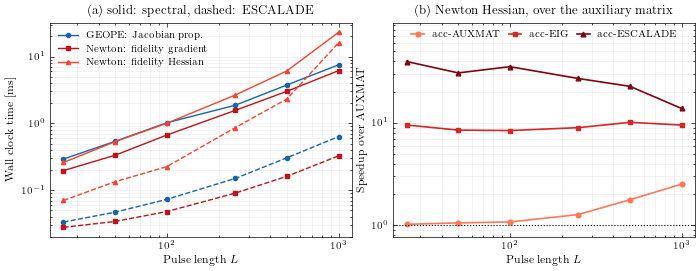


(a) speedup from ESCALADE, spectral / ESCALADE

      GEOPE: Jacobian prop.  Newton: fidelity gradient  Newton: fidelity Hessian
L                                                                               
25                     8.78                       7.06                      3.71
50                    11.47                       9.78                      3.97
100                   13.99                      13.96                      4.45
250                   12.45                      17.30                      3.08
500                   12.27                      18.68                      2.63
1000                  11.85                      18.84                      1.43
  GEOPE: Jacobian prop.          8.8x at L =   25  ->   11.8x at L = 1000
  Newton: fidelity gradient      7.1x at L =   25  ->   18.8x at L = 1000
  Newton: fidelity Hessian       3.7x at L =   25  ->    1.4x at L = 1000

The two *first-order* derivatives are the pieces that are purely per-gate, and
t

In [7]:
blues, reds = plt.cm.Blues, plt.cm.Reds
#: Panel (a): the three derivatives each method actually evaluates, in Figure 2's
#: colour families -- a piece keeps the colour it had there, so the two figures
#: read as one decomposition seen twice. `chart` is timed but not drawn: it is
#: the per-gate propagator all three contain, not a step of either method.
ESC_DRAWN = (
    ("GEOPE: Jacobian", blues(0.8), "o", "GEOPE: Jacobian prop."),
    ("Newton: gradient", reds(0.8), "s", "Newton: fidelity gradient"),
    ("Newton: Hessian", reds(0.6), "^", "Newton: fidelity Hessian"),
)
#: Panel (b): the Hessian routes, as a ladder in what each one replaces --
#: darker is more replaced and faster. Reds because the whole panel is the
#: *Newton* Hessian, which is red in panel (a) and in Figure 2. `AUXMAT` is not
#: a curve: it is the unit every one of these is divided by.
ACC_DRAWN = (
    ("acc-AUXMAT", reds(0.45), "o", "acc-AUXMAT"),
    ("acc-EIG", reds(0.7), "s", "acc-EIG"),
    ("acc-ESCALADE", reds(0.95), "^", "acc-ESCALADE"),
)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(TWO_COLUMN, 2.7))

for piece, colour, marker, name in ESC_DRAWN:
    for route, ls in (("live", "-"), ("ESCALADE", "--")):
        rows = esc_df[(esc_df["piece"] == piece) & (esc_df["route"] == route)]
        rows = rows.sort_values("L")
        ax_a.loglog(
            rows["L"], rows["seconds"] * 1e3, marker=marker, ls=ls, ms=3.0,
            color=colour, lw=1.0,
            label=name if route == "live" else None,
        )
ax_a.set_xlabel(r"Pulse length $L$")
ax_a.set_ylabel("Wall clock time [ms]")
ax_a.set_title("(a) solid: spectral, dashed: ESCALADE",
                fontsize=PANEL_LABEL_SIZE)
ax_a.grid(alpha=0.25, which="both", lw=0.4)
ax_a.legend(loc="upper left")

drawn = []
for route, colour, marker, name in ACC_DRAWN:
    rows = acc_speedup[route].sort_index()
    drawn.append(rows)
    ax_b.loglog(
        rows.index, rows.to_numpy(), marker=marker, ms=3.4,
        color=colour, lw=1.2, label=name,
    )

ax_b.axhline(1.0, color="black", ls=":", lw=0.8, zorder=2)
ax_b.set_xlabel(r"Pulse length $L$")
ax_b.set_ylabel("Speedup over AUXMAT")
ax_b.set_title("(b) Newton Hessian, over the auxiliary matrix",
                fontsize=PANEL_LABEL_SIZE)
# Room below parity so the dotted line is not the bottom spine, and a clear
# strip above every curve for the one-row legend.
low = min(float(s.min()) for s in drawn)
high = max(float(s.max()) for s in drawn)
ax_b.set_ylim(0.75 * low, 2.4 * high)
ax_b.grid(alpha=0.25, which="both", lw=0.4)
# One row, not a stack: the three curves already separate vertically, so a
# column of entries would have to sit somewhere among them.
ax_b.legend(
    ncol=len(ACC_DRAWN), loc="upper center", handlelength=1.3,
    borderpad=0.3, columnspacing=0.9,
)

fig.tight_layout(pad=0.4)
print(save_figure(fig, "fig4_escalade_speedup_n1"))
plt.show()

# Panel (a), compared *paired at each L*. Medians would hide the pairing, and
# the pairing is the claim: the same per-gate replacement sits inside all three,
# so what separates them is what else they do.
paired = pd.DataFrame(
    {name: esc_wide.loc[piece, "speedup"] for piece, _c, _m, name in ESC_DRAWN}
)
print("\n(a) speedup from ESCALADE, spectral / ESCALADE\n")
print(paired.round(2).to_string())

first, last = paired.iloc[0], paired.iloc[-1]
for _piece, _c, _m, name in ESC_DRAWN:
    print(
        f"  {name:<28s} {first[name]:5.1f}x at L = {paired.index[0]:4d}  ->  "
        f"{last[name]:5.1f}x at L = {paired.index[-1]:4d}"
    )
print(
    f"\nThe two *first-order* derivatives are the pieces that are purely per-gate, and"
    f"\nthey gain the most: {last['GEOPE: Jacobian prop.']:.0f}x and "
    f"{last['Newton: fidelity gradient']:.0f}x at L = {paired.index[-1]}. The Hessian "
    f"gains least ({last['Newton: fidelity Hessian']:.1f}x),"
    "\nand its factor *falls* with L, because the Gram contraction inside"
    "\n`hessian_vjp_propagator` is O(P^2) work the per-gate replacement does not touch"
    "\nand which comes to dominate -- the same second term Figure 2 charges to the"
    "\nNewton line."
    "\n\nEither way, ESCALADE multiplies both methods. It changes what an iteration"
    "\ncosts, not which method is cheaper, so Figure 2's comparison survives it intact."
)
print(
    f"\n(b) is that same Hessian against the method it replaces rather than against"
    f"\nthe spectral route. Over L in [{L_ACC[0]}, {L_ACC[-1]}], geometric mean:"
    f"\n  the pullback alone       {acc_geomean['acc-AUXMAT']:5.1f}x  and rising"
    f" with L,"
    f" the O(G^2) assembly being what it deletes"
    f"\n  + the spectral per-gate  {acc_geomean['acc-EIG']:5.1f}x  flat -- what geope"
    f" actually runs"
    f"\n  + ESCALADE's closed form {acc_geomean['acc-ESCALADE']:5.1f}x  and falling,"
    f" the O(P^2) Gram being what it does not"
    f"\n\nSo almost all of the {acc_geomean['acc-ESCALADE']:.0f}x is the closed form,"
    f" not"
    f" the pullback: on one qubit the"
    f"\nper-gate exponentials are the cost, and deleting a quadratic assembly that has"
    f"\nnot yet grown buys {acc_geomean['acc-AUXMAT']:.1f}x. The pullback is the term"
    f" that survives to large L,"
    f"\nand the only one of the two that would also grow with the dimension."
)